# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

Name : Vaishnavi Goyal

SRN : PES2UG24CS571

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
# Scanner protocol: 512 x 512 x 300
n_voxels = 512 * 512 * 300
# 16 bits = 2 bytes per voxel
scan_mb = (n_voxels * 2) / (1024 * 1024)

# TODO 2
# voxel spacing: 0.5 x 0.5 x 1.0 mm (dx, dy, dz)
# extent = size_in_voxels * spacing
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0) # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
# front-view: one ray per x-z pixel (512 x 300 rays), one sample per voxel step in y (512 steps)
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400




**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. **Geometric Distortion (Stretching):** If the voxel anisotropy is ignored, the pixels will be assumed to be isotropic (square). Since the z-axis voxel spacing (1.0 mm) is twice that of the x and y axes (0.5 mm), the anatomy will appear squished or flattened by 50% along the vertical (z) axis, severely distorting the physical shape and ratios of the head and organs.
2. **Incorrect Distance/Volume Measurements:** Quantitative analysis, such as measuring the diameter, area, or volume of a lesion in the coronal and sagittal planes, will yield highly inaccurate results because the scale factor along the z-direction is off by a factor of 2.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

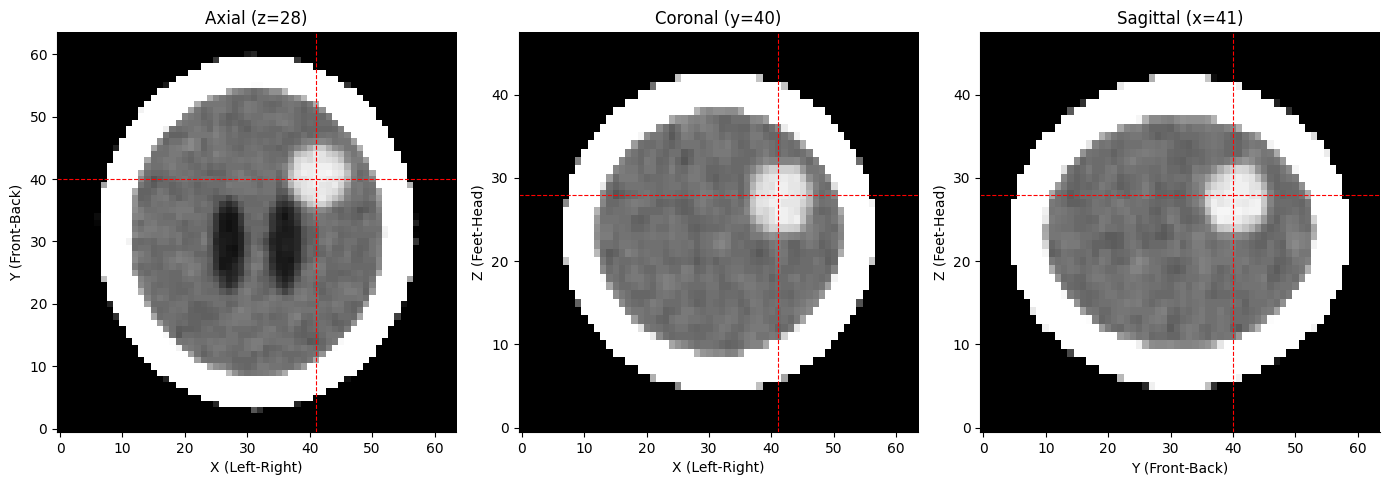

Computed centroid: (28, 40, 41)
Ground truth centroid: (27.50, 40.50, 41.50)
Centroid distance: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: Find candidates
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside_eroded = ndimage.binary_erosion(inside, iterations=3)
candidates = inside_eroded & (vol > 55) & (vol < 90)

# TODO 2: Label components and get centroid of the largest one
labeled, num_features = ndimage.label(candidates)
if num_features > 0:
    sizes = ndimage.sum(candidates, labeled, range(1, num_features + 1))
    largest_label = np.argmax(sizes) + 1
    lesion = (labeled == largest_label)
    cz, cy, cx = np.round(ndimage.center_of_mass(lesion)).astype(int)
else:
    lesion = np.zeros_like(vol, dtype=bool)
    cz, cy, cx = 0, 0, 0

# TODO 3: Plot axial, coronal, sagittal slices
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
W, L = 80, 40

# Axial: y vs x (fixed z = cz)
axes[0].imshow(window(vol[cz, :, :], W, L), cmap="gray", origin="lower")
axes[0].axhline(cy, color='red', linestyle='--', linewidth=0.8)
axes[0].axvline(cx, color='red', linestyle='--', linewidth=0.8)
axes[0].set_title(f"Axial (z={cz})")
axes[0].set_xlabel("X (Left-Right)")
axes[0].set_ylabel("Y (Front-Back)")

# Coronal: z vs x (fixed y = cy)
axes[1].imshow(window(vol[:, cy, :], W, L), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color='red', linestyle='--', linewidth=0.8)
axes[1].axvline(cx, color='red', linestyle='--', linewidth=0.8)
axes[1].set_title(f"Coronal (y={cy})")
axes[1].set_xlabel("X (Left-Right)")
axes[1].set_ylabel("Z (Feet-Head)")

# Sagittal: z vs y (fixed x = cx)
axes[2].imshow(window(vol[:, :, cx], W, L), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color='red', linestyle='--', linewidth=0.8)
axes[2].axvline(cy, color='red', linestyle='--', linewidth=0.8)
axes[2].set_title(f"Sagittal (x={cx})")
axes[2].set_xlabel("Y (Front-Back)")
axes[2].set_ylabel("Z (Feet-Head)")

plt.tight_layout()
plt.show()

# TODO 4 (evaluation only): Print centroid distance in mm
gt_lesion = (labels == 5)
gt_cz, gt_cy, gt_cx = ndimage.center_of_mass(gt_lesion)
dist_mm = np.sqrt(((cz - gt_cz) * SPACING[0])**2 + ((cy - gt_cy) * SPACING[1])**2 + ((cx - gt_cx) * SPACING[2])**2)
print(f"Computed centroid: ({cz}, {cy}, {cx})")
print(f"Ground truth centroid: ({gt_cz:.2f}, {gt_cy:.2f}, {gt_cx:.2f})")
print(f"Centroid distance: {dist_mm:.2f} mm")




**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The **partial-volume effect** occurs because a single voxel containing a mixture of high-intensity bone and low-intensity air or soft tissue gets averaged into a voxel of intermediate density. Consequently, the inner boundary (shell) of the skull results in voxels with CT numbers (55–90 HU) that overlap perfectly with the intensity range of the tumour. Without the erosion step, these skull-boundary voxels would be misidentified as candidates, fusing the skull with the brain tissue. Eroding the brain mask 3 times safely strips away this outer partial-volume shell, allowing us to isolate the actual brain interior.


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


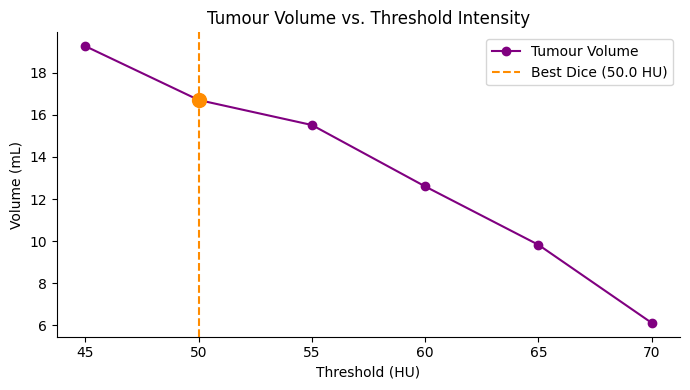

Volume range to report: 6.12 mL to 19.26 mL


In [4]:
truth = labels == 5
rows = []

# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    # Segment components of voxels > c
    binary_c = vol > c
    labeled_c, num_features_c = ndimage.label(binary_c)

    # Find component containing our lesion centroid (cz, cy, cx)
    target_label = labeled_c[cz, cy, cx]

    if target_label > 0:
        comp_mask = (labeled_c == target_label)
        v_count = np.sum(comp_mask)
        v_ml = v_count * VOXEL_MM3 / 1000.0

        # Dice overlap calculation
        intersection = np.sum(comp_mask & truth)
        dice = (2.0 * intersection) / (np.sum(comp_mask) + np.sum(truth))
    else:
        v_count = 0
        v_ml = 0.0
        dice = 0.0

    rows.append({"threshold": c, "voxels": v_count, "volume_mL": v_ml, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold"], table["volume_mL"], marker="o", linestyle="-", color="purple", label="Tumour Volume")
ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Volume (mL)")
ax.set_title("Tumour Volume vs. Threshold Intensity")

# Find and mark best dice threshold
best_idx = table["dice"].idxmax()
best_row = table.iloc[best_idx]
ax.axvline(best_row["threshold"], color="darkorange", linestyle="--", label=f"Best Dice ({best_row['threshold']} HU)")
ax.scatter(best_row["threshold"], best_row["volume_mL"], color="darkorange", s=100, zorder=5)
ax.legend()
plt.tight_layout()
plt.show()

# TODO 4
min_vol = table["volume_mL"].min()
max_vol = table["volume_mL"].max()
print(f"Volume range to report: {min_vol:.2f} mL to {max_vol:.2f} mL")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
To choose and justify the threshold \(c\), I would use standard clinical protocols (such as established Hounsfield Unit guidelines for glioblastoma or meningioma soft-tissue enhancement) and corroborate it with a radiologist's manual sample of the tumor core.
To visualize the uncertainty and ensure the surgeon doesn't treat a single value as absolute, we can:
1. **Overlay multiple transparent isosurfaces:** Plot a nested multi-layered 3D contour map (e.g., rendering thresholds 45, 55, and 65 HU with increasing transparency), showing a narrow "core" vs. a wide "penumbra".
2. **Display confidence interval bands:** Provide the tumor board with an explicit range graph (volume vs. threshold) and color-code the slices with probabilistic or fuzzy boundary outlines showing high/low probability of tumor margins.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

Rendering bone (front view)... 
Rendering custom TF (front view)... 
Rendering custom TF (top view)... 


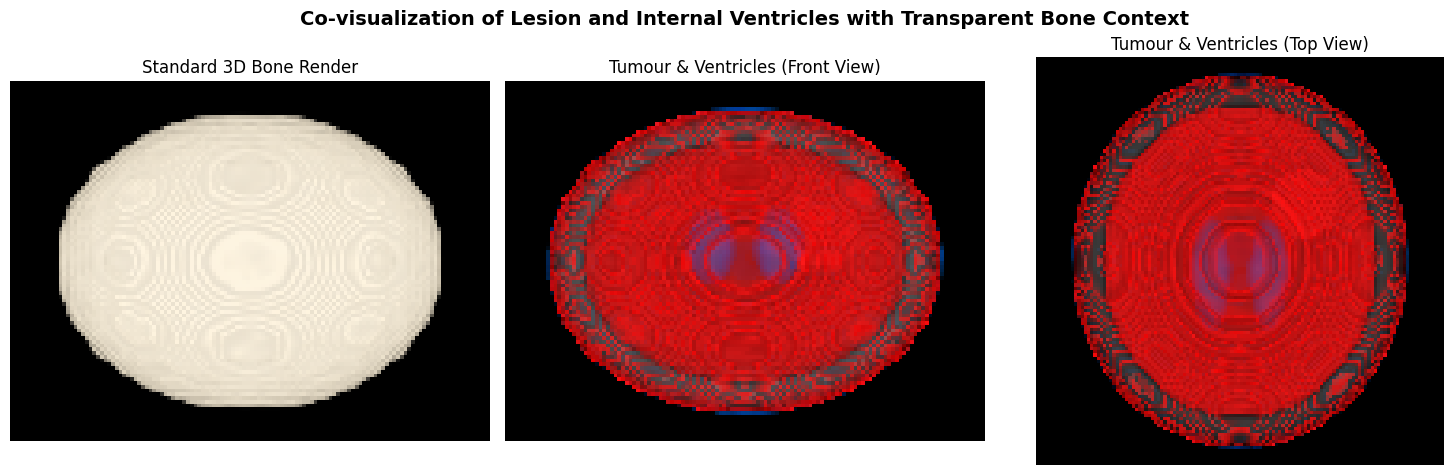

In [8]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
# CSF ≈ 5–20 HU (faint, blue)
# Tumour ≈ 50–75 HU (highly opaque, red)
# Bone > 300 HU (almost transparent context)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (0, (0, 0, 0), 0),
    (5, (0, 0.5, 1.0), 0.05),     # faint blue CSF start
    (20, (0, 0.3, 1.0), 0.05),  # faint blue CSF
    (25, (0, 0, 0), 0),         # transparent soft tissue
    (44, (0, 0, 0), 0),         # remain transparent below tumour
    (45, (1.0, 0.1, 0.1), 0.3), # red tumour onset
    (70, (1.0, 0.0, 0.0), 0.6),    # solid red tumour
    (150, (0, 0, 0), 0),           # suppress other tissue
    (300, (1.0, 1.0, 1.0), 0.005), # highly transparent bone background
    (1500, (1.0, 1.0, 1.0), 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: bone render | your TF front view | your TF top view
print("Rendering bone (front view)... ")
img_bone, _ = render(vol, bone_tf, axis=1)
axes[0].imshow(img_bone, origin="lower")
axes[0].set_title("Standard 3D Bone Render")
axes[0].axis("off")

print("Rendering custom TF (front view)... ")
img_front, _ = render(vol, tumour_tf, axis=1)
axes[1].imshow(img_front, origin="lower")
axes[1].set_title("Tumour & Ventricles (Front View)")
axes[1].axis("off")

print("Rendering custom TF (top view)... ")
img_top, _ = render(vol, tumour_tf, axis=0)
axes[2].imshow(img_top, origin="lower")
axes[2].set_title("Tumour & Ventricles (Top View)")
axes[2].axis("off")

# TODO 4: suptitle
plt.suptitle("Co-visualization of Lesion and Internal Ventricles with Transparent Bone Context", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
This artifact is caused by the **partial-volume effect** along the inner boundary of the skull, where voxels containing a mixture of high-density bone and low-density brain matter end up with average CT numbers (45–75 HU) that mimic the tumor's intensity signature.
To completely eliminate this artifact, we can apply **spatial segmentation masking** (Slide 31) to mask out everything outside the eroded brain region before rendering. A transfer function alone cannot solve this because it operates strictly on voxel intensities (values) and lacks spatial context; it is completely blind to whether a voxel of 60 HU is inside the actual lesion or on the boundary of the skull.



## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
To the Neuro-Oncology Tumour Board:

We have identified a lesion localized in the right cerebral hemisphere, with a centroid located at coordinates (28, 40, 41) in voxel space. Depending on the threshold selection (ranging from 45 to 70 HU), the computed tumor volume ranges from 6.12 mL to 19.26 mL (with the most accurate anatomical overlap at 50 HU, yielding 16.70 mL). I recommend opening the clinical review session with the Multiplanar Reconstruction (MPR) slices rather than the 3D projection, because planar slicing exposes internal structures directly, bypasses the spatial occlusion that obscures the tumor's interior, and enables precise geometric measurement of the core. While our custom 3D volume-rendered views successfully show the spatial relationship of the tumor in red against the blue ventricles, the board must remain cautious of its limitations: the 3D rendering suffers from partial-volume artifacts, producing a false red ring at the interior boundary of the skull where different tissue types overlap in the same intensity range.
